In [4]:
# Week 5:Model Evaluation and Hyperparameter Tuning
# Step 1: Import Libraries

import kagglehub
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Step 2: LOAD CARDEKHO DATASET


path = kagglehub.dataset_download(
    "nehalbirla/vehicle-dataset-from-cardekho"
)

file_path = os.path.join(path, "car data.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [6]:
# Step3: DATASET INFORMATION

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate Rows:
2


In [7]:
# Step 4: DATA CLEANING

print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))

Rows before removing duplicates: 301
Rows after removing duplicates: 299


In [8]:
# Step 5: CREATE TARGET VARIABLE

# Convert Transmission into numerical labels
# Manual = 0
# Automatic = 1

df["Transmission"] = df["Transmission"].map({
    "Manual": 0,
    "Automatic": 1
})

print("Target variable created successfully!")

print("\nTransmission distribution:")
print(df["Transmission"].value_counts())

print("\nTransmission proportions:")
print(df["Transmission"].value_counts(normalize=True))

Target variable created successfully!

Transmission distribution:
Transmission
0    260
1     39
Name: count, dtype: int64

Transmission proportions:
Transmission
0    0.869565
1    0.130435
Name: proportion, dtype: float64


In [9]:
# Step 6: FEATURE AND TARGET SELECTION

X = df.drop(
    columns=["Transmission", "Car_Name"]
)

y = df["Transmission"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Transmission")

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:
['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Owner']

Target:
Transmission

Feature shape: (299, 7)
Target shape: (299,)


In [10]:
# Step 7: ENCODE CATEGORICAL FEATURES

X = pd.get_dummies(
    X,
    columns=["Fuel_Type", "Seller_Type"],
    drop_first=True
)

print("Encoding completed successfully!")

print("\nEncoded feature columns:")
print(X.columns.tolist())

print("\nEncoded dataset shape:", X.shape)

Encoding completed successfully!

Encoded feature columns:
['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual']

Encoded dataset shape: (299, 8)


In [11]:
# Step 8: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 239
Testing samples: 60

Training target distribution:
Transmission
0    208
1     31
Name: count, dtype: int64

Testing target distribution:
Transmission
0    52
1     8
Name: count, dtype: int64


In [12]:
# Step 9: FEATURE SCALING

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [13]:
# Step 10: DEFINE MULTIPLE CLASSIFICATION MODELS

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [14]:
# Step 11: TRAIN MULTIPLE MODELS

trained_models = {}

for name, model in models.items():

    # Tree-based models don't require scaling,
    # but using the same prepared feature matrix
    # keeps the experiment consistent.
    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!")

print("\nAll models have been trained.")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!

All models have been trained.


In [15]:
# Step 12: MODEL EVALUATION

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )
    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.883333,0.6,0.375,0.461538,0.668269
1,Random Forest,0.900000,1.0,0.250,0.400000,0.852163
2,Gradient Boosting,0.900000,1.0,0.250,0.400000,0.842548
3,Logistic Regression,0.883333,1.0,0.125,0.222222,0.665865


In [16]:
# Step 13: PROFESSIONAL RESULTS TABLE

results_display = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

for column in metric_columns:
    results_display[column] = (
        results_display[column] * 100
    ).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,88.33,60.0,37.5,46.15,66.83
1,Random Forest,90.00,100.0,25.0,40.00,85.22
2,Gradient Boosting,90.00,100.0,25.0,40.00,84.25
3,Logistic Regression,88.33,100.0,12.5,22.22,66.59


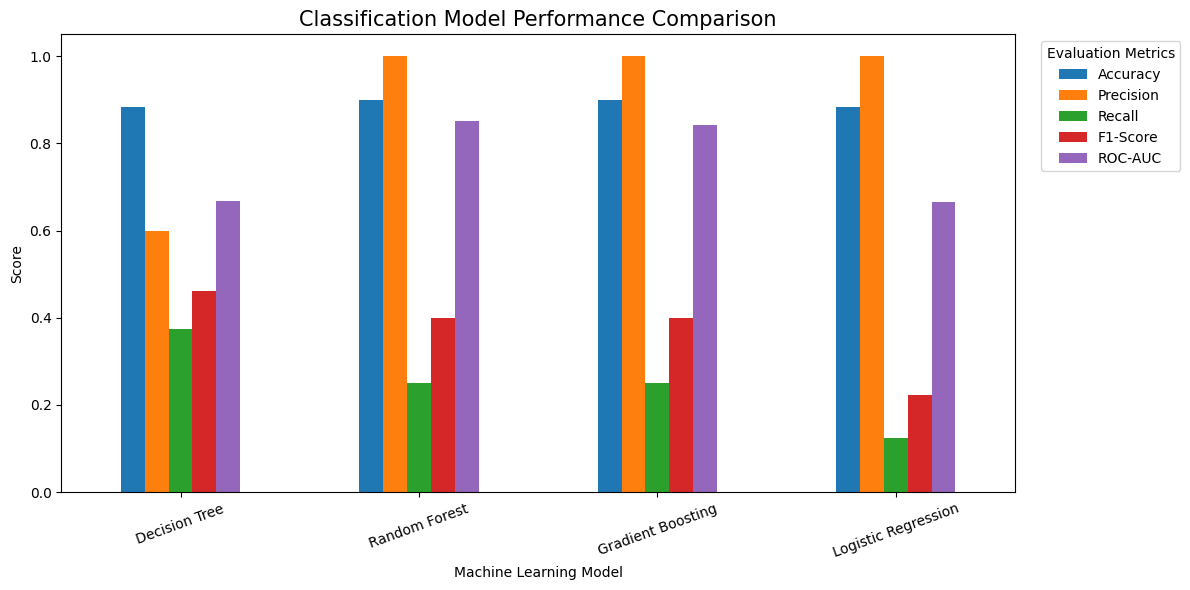

In [17]:
# Step 14: MODEL PERFORMANCE COMPARISON

plot_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Classification Model Performance Comparison",
    fontsize=15
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)
plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [18]:
# CELL 15: SELECT BEST BASELINE MODEL

best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(),
    "Model"
]

best_baseline_model = trained_models[best_model_name]

print("Best baseline model:", best_model_name)

print(
    "Best baseline F1-Score:",
    round(
        results_df.loc[
            results_df["Model"] == best_model_name,
            "F1-Score"
        ].iloc[0],
        4
    )
)

Best baseline model: Decision Tree
Best baseline F1-Score: 0.4615


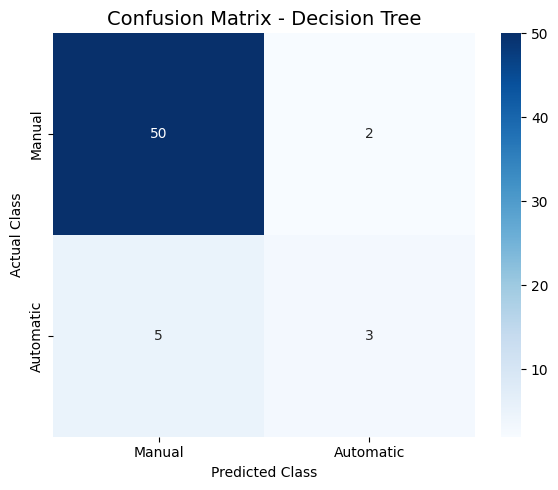

In [19]:
# Step 16: CONFUSION MATRIX

best_predictions = best_baseline_model.predict(
    X_test_scaled
)

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Manual", "Automatic"],
    yticklabels=["Manual", "Automatic"]
)

plt.title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=14
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [20]:
# Step 17: CLASSIFICATION REPORT

print(
    f"Classification Report - {best_model_name}\n"
)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Manual", "Automatic"],
        zero_division=0
    )
)

Classification Report - Decision Tree

              precision    recall  f1-score   support

      Manual       0.91      0.96      0.93        52
   Automatic       0.60      0.38      0.46         8

    accuracy                           0.88        60
   macro avg       0.75      0.67      0.70        60
weighted avg       0.87      0.88      0.87        60



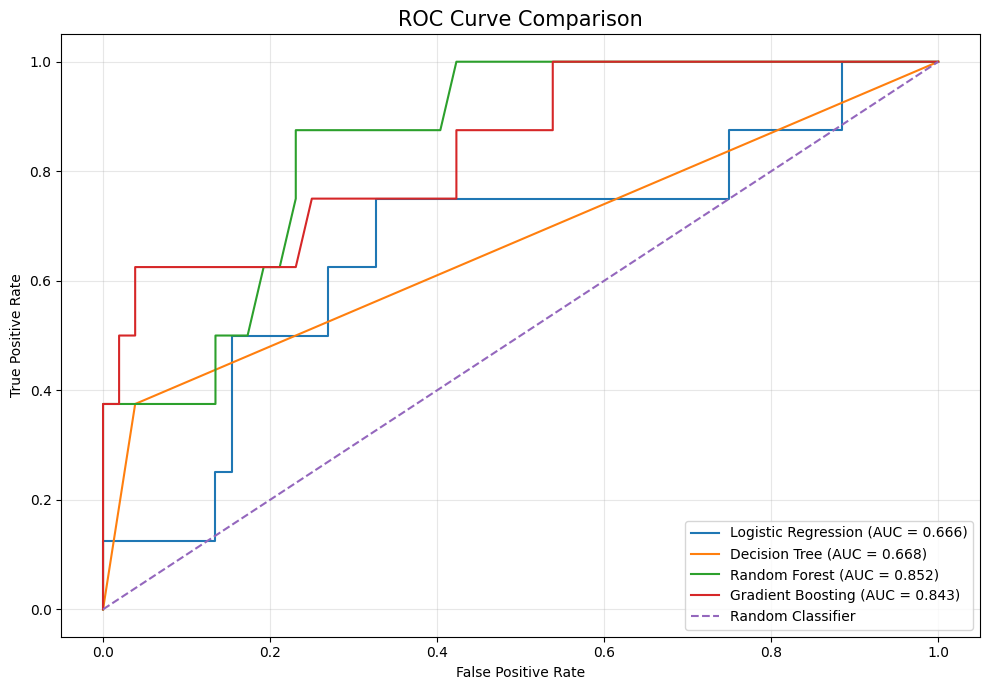

In [21]:
# Step 18: ROC CURVE COMPARISON


plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    probabilities = model.predict_proba(
        X_test_scaled
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title(
    "ROC Curve Comparison",
    fontsize=15
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Step 19: RANDOM FOREST HYPERPARAMETER TUNING

rf = RandomForestClassifier(
    random_state=42
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_scaled,
    y_train
)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Hyperparameter tuning completed!


In [24]:
# CELL 20: BEST HYPERPARAMETERS

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(
    round(
        grid_search.best_score_,
        4
    )
)

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 300}

Best Cross-Validation F1-Score:
0.5305


In [26]:
# Step 21: OPTIMIZED MODEL

optimized_model = grid_search.best_estimator_

print("Optimized Random Forest model created successfully!")
print(optimized_model)

Optimized Random Forest model created successfully!
RandomForestClassifier(min_samples_split=10, n_estimators=300, random_state=42)


In [27]:
# Step 22: EVALUATE OPTIMIZED MODEL

optimized_predictions = optimized_model.predict(
    X_test_scaled
)

optimized_probabilities = optimized_model.predict_proba(
    X_test_scaled
)[:, 1]

optimized_accuracy = accuracy_score(
    y_test,
    optimized_predictions
)

optimized_precision = precision_score(
    y_test,
    optimized_predictions,
    zero_division=0
)

optimized_recall = recall_score(
    y_test,
    optimized_predictions,
    zero_division=0
)

optimized_f1 = f1_score(
    y_test,
    optimized_predictions,
    zero_division=0
)

optimized_auc = roc_auc_score(
    y_test,
    optimized_probabilities
)

print("Optimized Model Performance")
print("--------------------------------")

print(f"Accuracy  : {optimized_accuracy:.4f}")
print(f"Precision : {optimized_precision:.4f}")
print(f"Recall    : {optimized_recall:.4f}")
print(f"F1-Score  : {optimized_f1:.4f}")
print(f"ROC-AUC   : {optimized_auc:.4f}")

Optimized Model Performance
--------------------------------
Accuracy  : 0.9000
Precision : 1.0000
Recall    : 0.2500
F1-Score  : 0.4000
ROC-AUC   : 0.8510


In [28]:
# CELL 23: BEFORE VS AFTER TUNING

rf_baseline = trained_models["Random Forest"]

rf_baseline_predictions = rf_baseline.predict(
    X_test_scaled
)

rf_baseline_probabilities = rf_baseline.predict_proba(
    X_test_scaled
)[:, 1]

before_tuning = {
    "Accuracy": accuracy_score(
        y_test,
        rf_baseline_predictions
    ),
    "Precision": precision_score(
        y_test,
        rf_baseline_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        rf_baseline_predictions,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_test,
        rf_baseline_predictions,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        rf_baseline_probabilities
    )
}

after_tuning = {
    "Accuracy": optimized_accuracy,
    "Precision": optimized_precision,
    "Recall": optimized_recall,
    "F1-Score": optimized_f1,
    "ROC-AUC": optimized_auc
}

comparison_df = pd.DataFrame({
    "Before Tuning": before_tuning,
    "After Tuning": after_tuning
})

comparison_df

,Before Tuning,After Tuning
Accuracy,0.900000,0.900000
Precision,1.000000,1.000000
Recall,0.250000,0.250000
F1-Score,0.400000,0.400000
ROC-AUC,0.852163,0.850962


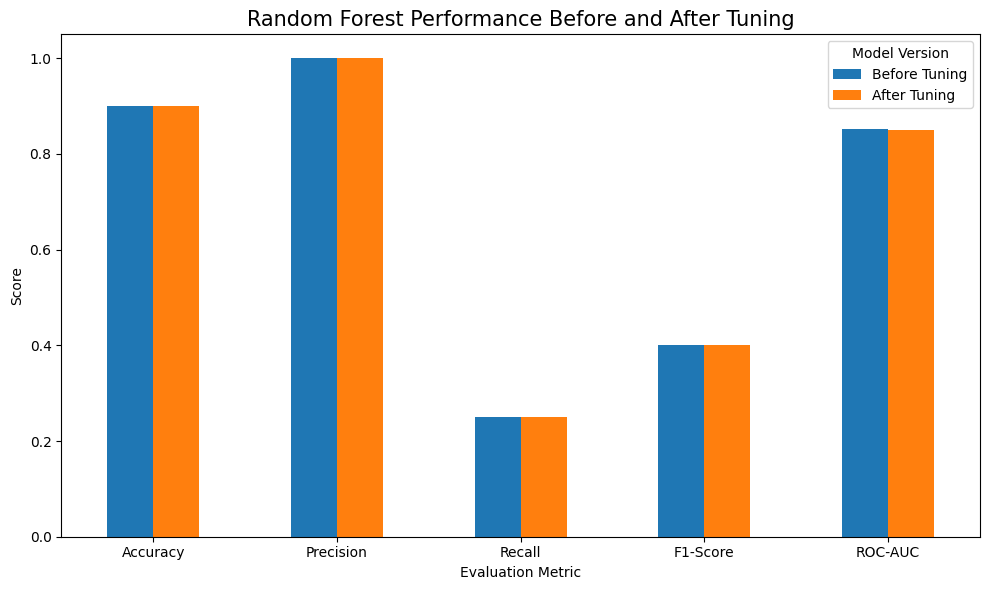

In [29]:
# Step 24: BEFORE VS AFTER TUNING GRAPH

comparison_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Random Forest Performance Before and After Tuning",
    fontsize=15
)

plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(
    title="Model Version"
)

plt.tight_layout()
plt.show()

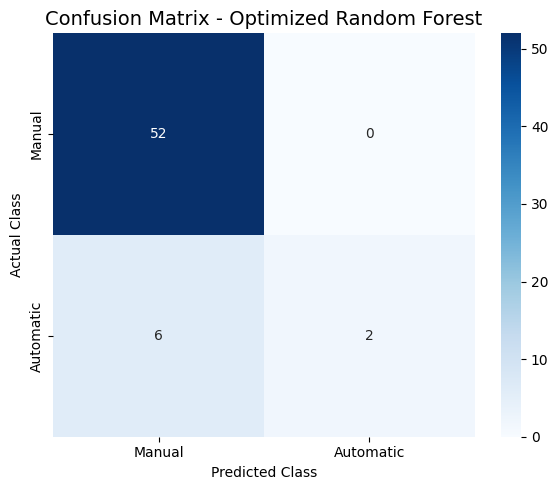

In [30]:
# Step 25: OPTIMIZED MODEL CONFUSION MATRIX

optimized_cm = confusion_matrix(
    y_test,
    optimized_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    optimized_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Manual", "Automatic"],
    yticklabels=["Manual", "Automatic"]
)

plt.title(
    "Confusion Matrix - Optimized Random Forest",
    fontsize=14
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [31]:
# Step 26: FINAL CLASSIFICATION REPORT

print("FINAL OPTIMIZED MODEL")
print("======================")

print(
    classification_report(
        y_test,
        optimized_predictions,
        target_names=["Manual", "Automatic"],
        zero_division=0
    )
)

FINAL OPTIMIZED MODEL
              precision    recall  f1-score   support

      Manual       0.90      1.00      0.95        52
   Automatic       1.00      0.25      0.40         8

    accuracy                           0.90        60
   macro avg       0.95      0.62      0.67        60
weighted avg       0.91      0.90      0.87        60



In [32]:
# Step 27: FEATURE IMPORTANCE

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": optimized_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                  Feature  Importance
2           Present_Price    0.403161
1           Selling_Price    0.299629
3              Kms_Driven    0.189109
0                    Year    0.070306
5        Fuel_Type_Diesel    0.010764
4                   Owner    0.010113
6        Fuel_Type_Petrol    0.009021
7  Seller_Type_Individual    0.007897


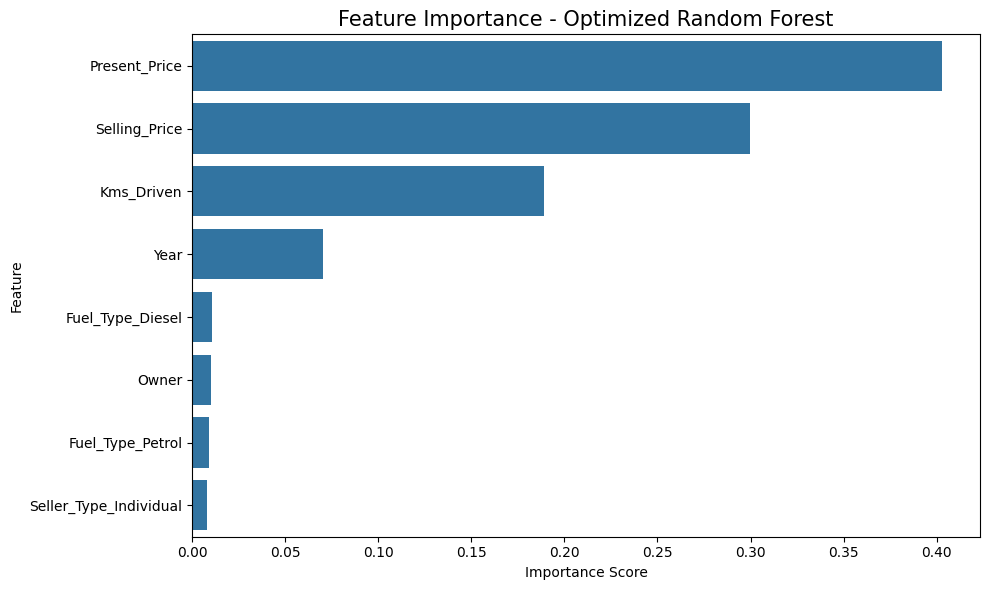

In [33]:
# Step 28: FEATURE IMPORTANCE VISUALIZATION

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance - Optimized Random Forest",
    fontsize=15
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [35]:
# Step 29: FINAL EVALUATION REPORT

final_report = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        optimized_accuracy,
        optimized_precision,
        optimized_recall,
        optimized_f1,
        optimized_auc
    ]
})

final_report["Percentage"] = (
    final_report["Score"] * 100
).round(2)

final_report

,Metric,Score,Percentage
0,Accuracy,0.900000,90.0
1,Precision,1.000000,100.0
2,Recall,0.250000,25.0
3,F1-Score,0.400000,40.0
4,ROC-AUC,0.850962,85.1


In [36]:
# Step 30: SAVE OPTIMIZED MODEL

import joblib

joblib.dump(
    optimized_model,
    "optimized_random_forest_model.pkl"
)

joblib.dump(
    scaler,
    "feature_scaler.pkl"
)

print("Optimized model saved successfully!")
print("Scaler saved successfully!")

Optimized model saved successfully!
Scaler saved successfully!
